In [60]:
import numpy as np
import matplotlib.pyplot as mp
import pandas as pd
import seaborn as sns

In [61]:
df = pd.read_csv("exoplanet_data.csv", comment="#")

In [62]:
df.shape

(599, 92)

In [63]:
#shape of my data is 599 rows and 92 columns 

In [64]:
print(df.columns.tolist())

['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'soltype', 'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_masslim', 'st_met', 'st_meterr1', 'st_meterr2', 'st_metlim', 'st_metratio', 'st_logg', 'st

In [65]:
# sy_snum, sypnum, disc_facility, soltype, pl_refname

In [66]:
#planet name: pl_name, default name for a planet
#host name: hostname, name of star that a planet orbits
#discovery method: discoverymethod, how the planet was identified 
#spectral type: st_spectype, how host stars are classified 
#equilibrium temp: pl_eqt, the planets equilibrium temp
#planet mass [jupiter]: pl_bmassj, jupiter's mass

In [67]:
col = ["pl_name", "hostname", "discoverymethod", "st_spectype", "pl_eqt", "pl_bmassj"]
dcn = df[col]

In [68]:
dcn = dcn.dropna()

In [69]:
print(dcn.shape)

(77, 6)


In [70]:
#shape is 77 rows by 6 columns

In [71]:
print(dcn.head())

    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
3  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
4  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
6  DMPP-1 d   DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
8  DMPP-1 e   DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
9  DMPP-2 b   DMPP-2  Radial Velocity        F5 V  1000.0   0.437000


In [72]:
print(dcn.tail())

         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
575   WASP-185 b   WASP-185          Transit        G0 V  1160.0      0.980
580   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0      1.000
584   WASP-192 b   WASP-192          Transit        G0 V  1620.0      2.300
585       XO-7 b       XO-7          Transit        G0 V  1743.0      0.709
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0      6.310


In [73]:
print(dcn.columns.tolist())

['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']


In [74]:
dcn["discoverymethod"].value_counts()

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64

In [75]:
#3 discovery mehtods. Transit takes the lead with 62, followed by Radial Velocity 13, and lastly Imaging 2

In [76]:
#transit is when exoplanets are discovered by tracking a dip in a known stars brightness. Radial Velocity is when the light specturm shifts due to gravity so we know there is an object interfering. Imaging is when telescopes are used. 

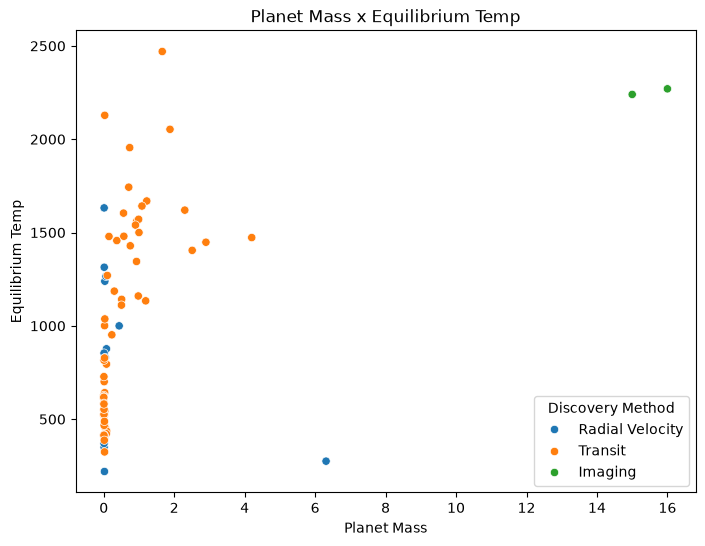

In [83]:
mp.figure(figsize=(8,6))
sns.scatterplot(data = dcn, x = "pl_bmassj", y = "pl_eqt", hue = "discoverymethod")
mp.xlabel("Planet Mass")
mp.ylabel("Equilibrium Temp")
mp.title("Planet Mass x Equilibrium Temp")
mp.legend(title = "Discovery Method")
mp.show()

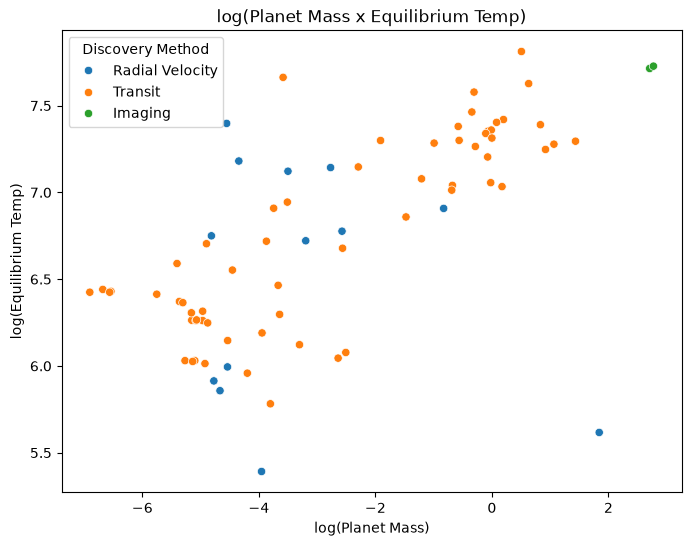

In [85]:
mp.figure(figsize=(8,6))
sns.scatterplot(x=np.log(dcn["pl_bmassj"]), y = np.log(dcn["pl_eqt"]), hue = dcn["discoverymethod"])
mp.xlabel("log(Planet Mass)")
mp.ylabel("log(Equilibrium Temp)")
mp.title("log(Planet Mass x Equilibrium Temp)")
mp.legend(title = "Discovery Method")
mp.show()

In [86]:
#more likley to be small.

In [88]:
mass = dcn[dcn["pl_bmassj"] > 5]
cold = mass.loc[mass["pl_eqt"].idxmin()]
print(cold)

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object


In [89]:
print(cold["pl_name"])

eps Ind A b


In [90]:
print(cold.name)

597


In [92]:
print(cold["pl_eqt"])

275.0


In [93]:
print(cold["pl_bmassj"])

6.31


In [95]:
print(cold["st_spectype"])

K5 V


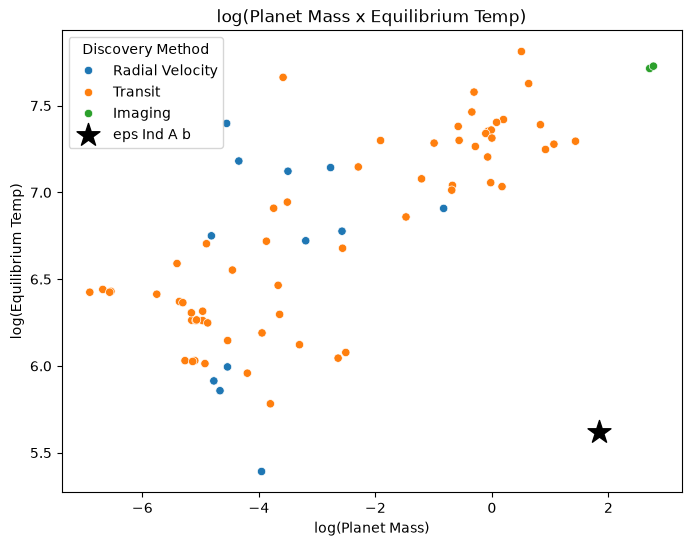

In [100]:
mp.figure(figsize = (8, 6))
sns.scatterplot(x = np.log(dcn["pl_bmassj"]), y=np.log(dcn["pl_eqt"]), hue = dcn["discoverymethod"])
mp.scatter(np.log(cold["pl_bmassj"]), np.log(cold["pl_eqt"]), color = "black", marker = "*", s = 300, label = cold["pl_name"])
mp.xlabel("log(Planet Mass)")
mp.ylabel("log(Equilibrium Temp)")
mp.title("log(Planet Mass x Equilibrium Temp)")
mp.legend(title = "Discovery Method")
mp.show()

In [101]:
#title is "a temputure super jupiter imaged with JWST in the mid-infered. 

In [102]:
#the abstract descirbes that a massive exoplanet was found 

In [103]:
#I belive it does.

In [104]:
#the planet I found is very big and very cold which matches the paper. 